Aiyanna Ranch 10/21/2026
Does popularity impact engagment on Bluesky?
I want to investigate whether Bluesky accounts with higher follower counts receive more engagement on their posts than accounts with lower follower counts. Social media popularity may influence how widely content is seen and how frequently other users interact with it. However, follower count alone may not explain why some posts receive more engagement than others. My hypothesis is that Bluesky accounts with higher follower counts tend to receive more engagement, measured by likes, reposts, and replies, on their posts. The theoretical application of this hypothesis is to explore the relationship between audience size and social media engagement. The statistical application is to compare follower counts with engagement to see potential patterns or relationships. The independent variable is the account's follower count, and the dependent variable is post engagement. Engagement will be measured using likes, reposts, and replies, which can also be combined into a total engagement variable.

This report uses two public endpoints from the Bluesky API: app.bsky.actor.getProfile and app.bsky.feed.getAuthorFeed. These endpoints provide information that can be combined to see the relationship between follower counts and post engagement. The app.bsky.actor.getProfile endpoint gives account information like the account's handle, unique identifier (DID), follower count, following count, and total post count. The follower count will be used as a measure of account popularity. The app.bsky.feed.getAuthorFeed endpoint returns posts and associated information for a specified account. The relevant response objects are the post record, author information, like count, repost count, reply count, and post URI. These values will be used to calculate engagement for individual posts. The two datasets can be combined using a shared account identifier, such as the author's DID. The data may be reliable because it comes directly from Bluesky's public API and provides information that can be consistently extracted. However, the data has limitations. Information can change over time, and the API returns only a limited selection of posts per request. The accounts selected for this report may not represent all Bluesky users. The analysis will therefore describe patterns in the collected sample rather than establish that follower count causes engagement.

In [1]:
import requests
import pandas as pd
import matplotlib.pyplot as plt

The first API request collects profile information for the Bluesky accounts. The account handle will be used to retrieve the profile, and the response will provide the account's DID and follower count.

In [3]:
import requests
import pandas as pd

url = "https://public.api.bsky.app/xrpc/app.bsky.actor.getProfile"

accounts = [
    "xelahart.bsky.social",
    "markhamillofficial.bsky.social",
    "ebiconstudio.bsky.social",
    "capnjackresists.bsky.social",
    "dreamcatcher01.bsky.social"
]

profiles = []

for account in accounts:
    params = {"actor": account}
    response = requests.get(url, params=params)

    print(account, response.status_code)

    if response.status_code == 200:
        profile_data = response.json()

        profiles.append({
            "handle": profile_data.get("handle"),
            "did": profile_data.get("did"),
            "followers": profile_data.get("followersCount", 0),
            "following": profile_data.get("followsCount", 0),
            "total_posts": profile_data.get("postsCount", 0)
        })

    else:
        print("Could not retrieve profile:", account)

profiles_df = pd.DataFrame(profiles)

profiles_df

xelahart.bsky.social 200
markhamillofficial.bsky.social 200
ebiconstudio.bsky.social 200
capnjackresists.bsky.social 200
dreamcatcher01.bsky.social 200


,handle,did,followers,following,total_posts
0,xelahart.bsky.social,did:plc:2zmlpiynrrzsqsq2m3b4waxe,39461,20405,41856
1,markhamillofficial.bsky.social,did:plc:xyddpg6usmgh2t2jgf4e37yk,1383324,3331,2146
2,ebiconstudio.bsky.social,did:plc:ynd2cmkfndbft6u555ez3vtk,35,13,3
3,capnjackresists.bsky.social,did:plc:sqqmj43yipxkbd47kgg3qr3h,28502,16320,15152
4,dreamcatcher01.bsky.social,did:plc:mt4sghcnbkxiwabgjraumtbp,36013,15552,82428


In [4]:
response.status_code

200

The second API endpoint retrieves posts associated with a specified Bluesky account. I will use it to collect the post identifiers, publication dates, post text, and engagement metrics, including likes, reposts, and replies. Then, I will request up to 30 feed entries for each account and focus on posts authored by the selected accounts rather than reposts or replies.

In [5]:
posts_url = "https://public.api.bsky.app/xrpc/app.bsky.feed.getAuthorFeed"

posts = []

for _, account in profiles_df.iterrows():
    params = {
        "actor": account["did"],
        "limit": 30,
        "filter": "posts_no_replies"
    }

    response = requests.get(posts_url, params=params, timeout=30)

    print(account["handle"], response.status_code)

    if response.status_code == 200:
        feed_data = response.json()

        for item in feed_data.get("feed", []):
            post = item.get("post", {})
            author = post.get("author", {})

            # Keep only posts written by the selected account
            if author.get("did") != account["did"]:
                continue

            record = post.get("record", {})

            posts.append({
                "did": author.get("did"),
                "handle": author.get("handle"),
                "post_uri": post.get("uri"),
                "text": record.get("text", ""),
                "created_at": record.get("createdAt"),
                "likes": post.get("likeCount", 0),
                "reposts": post.get("repostCount", 0),
                "replies": post.get("replyCount", 0)
            })

    else:
        print("Feed request failed for", account["handle"])

posts_df = pd.DataFrame(posts)

posts_df.head()

xelahart.bsky.social 200
markhamillofficial.bsky.social 200
ebiconstudio.bsky.social 200
capnjackresists.bsky.social 200
dreamcatcher01.bsky.social 200


,did,handle,post_uri,text,created_at,likes,reposts,replies
0,did:plc:2zmlpiynrrzsqsq2m3b4waxe,xelahart.bsky.social,at://did:plc:2zmlpiynrrzsqsq2m3b4waxe/app.bsky...,@garthtoons.bsky.social,2026-10-22T00:15:21.871Z,0,0,0
1,did:plc:2zmlpiynrrzsqsq2m3b4waxe,xelahart.bsky.social,at://did:plc:2zmlpiynrrzsqsq2m3b4waxe/app.bsky...,@dccartoonist.bsky.social,2026-10-22T00:10:51.831Z,14,3,0
2,did:plc:2zmlpiynrrzsqsq2m3b4waxe,xelahart.bsky.social,at://did:plc:2zmlpiynrrzsqsq2m3b4waxe/app.bsky...,🔥🔥🔥,2026-10-21T23:43:04.413Z,1260,326,88
3,did:plc:2zmlpiynrrzsqsq2m3b4waxe,xelahart.bsky.social,at://did:plc:2zmlpiynrrzsqsq2m3b4waxe/app.bsky...,I’m glad Todd Blanche has his mugshot face per...,2026-10-21T23:36:47.075Z,824,147,52
4,did:plc:2zmlpiynrrzsqsq2m3b4waxe,xelahart.bsky.social,at://did:plc:2zmlpiynrrzsqsq2m3b4waxe/app.bsky...,"“Days of Our Lives”, but still. 😂😂😂",2026-10-21T23:32:38.277Z,79,6,16


Before combining the datasets, I make sure the API requests returned usable information. I will check the number of profiles and posts collected, examine sample rows, and identify missing values that could affect the analysis.

In [6]:
print("Number of profiles:", len(profiles_df))
print("Number of posts:", len(posts_df))

print("\nProfile data:")
display(profiles_df)

print("\nFirst five posts:")
display(posts_df.head())

print("\nMissing values in post data:")
display(posts_df.isna().sum())

Number of profiles: 5
Number of posts: 104

Profile data:


,handle,did,followers,following,total_posts
0,xelahart.bsky.social,did:plc:2zmlpiynrrzsqsq2m3b4waxe,39461,20405,41856
1,markhamillofficial.bsky.social,did:plc:xyddpg6usmgh2t2jgf4e37yk,1383324,3331,2146
2,ebiconstudio.bsky.social,did:plc:ynd2cmkfndbft6u555ez3vtk,35,13,3
3,capnjackresists.bsky.social,did:plc:sqqmj43yipxkbd47kgg3qr3h,28502,16320,15152
4,dreamcatcher01.bsky.social,did:plc:mt4sghcnbkxiwabgjraumtbp,36013,15552,82428



First five posts:


,did,handle,post_uri,text,created_at,likes,reposts,replies
0,did:plc:2zmlpiynrrzsqsq2m3b4waxe,xelahart.bsky.social,at://did:plc:2zmlpiynrrzsqsq2m3b4waxe/app.bsky...,@garthtoons.bsky.social,2026-10-22T00:15:21.871Z,0,0,0
1,did:plc:2zmlpiynrrzsqsq2m3b4waxe,xelahart.bsky.social,at://did:plc:2zmlpiynrrzsqsq2m3b4waxe/app.bsky...,@dccartoonist.bsky.social,2026-10-22T00:10:51.831Z,14,3,0
2,did:plc:2zmlpiynrrzsqsq2m3b4waxe,xelahart.bsky.social,at://did:plc:2zmlpiynrrzsqsq2m3b4waxe/app.bsky...,🔥🔥🔥,2026-10-21T23:43:04.413Z,1260,326,88
3,did:plc:2zmlpiynrrzsqsq2m3b4waxe,xelahart.bsky.social,at://did:plc:2zmlpiynrrzsqsq2m3b4waxe/app.bsky...,I’m glad Todd Blanche has his mugshot face per...,2026-10-21T23:36:47.075Z,824,147,52
4,did:plc:2zmlpiynrrzsqsq2m3b4waxe,xelahart.bsky.social,at://did:plc:2zmlpiynrrzsqsq2m3b4waxe/app.bsky...,"“Days of Our Lives”, but still. 😂😂😂",2026-10-21T23:32:38.277Z,79,6,16



Missing values in post data:


did           0
handle        0
post_uri      0
text          0
created_at    0
likes         0
reposts       0
replies       0
dtype: int64

In [15]:
analysis_df = pd.merge(
    posts_df,
    profiles_df[["did", "followers"]],
    on="did",
    how="inner"
)

analysis_df["total_engagement"] = (
    analysis_df["likes"]
    + analysis_df["reposts"]
    + analysis_df["replies"]
)

analysis_df["created_at"] = pd.to_datetime(
    analysis_df["created_at"],
    errors="coerce",
    utc=True
)

analysis_df = analysis_df.drop_duplicates(
    subset="post_uri"
)

analysis_df = analysis_df.reset_index(drop=True)

analysis_df.head()

,did,handle,post_uri,text,created_at,likes,reposts,replies,followers,total_engagement
0,did:plc:2zmlpiynrrzsqsq2m3b4waxe,xelahart.bsky.social,at://did:plc:2zmlpiynrrzsqsq2m3b4waxe/app.bsky...,@garthtoons.bsky.social,2026-10-22 00:15:21.871000+00:00,0,0,0,39461,0
1,did:plc:2zmlpiynrrzsqsq2m3b4waxe,xelahart.bsky.social,at://did:plc:2zmlpiynrrzsqsq2m3b4waxe/app.bsky...,@dccartoonist.bsky.social,2026-10-22 00:10:51.831000+00:00,14,3,0,39461,17
2,did:plc:2zmlpiynrrzsqsq2m3b4waxe,xelahart.bsky.social,at://did:plc:2zmlpiynrrzsqsq2m3b4waxe/app.bsky...,🔥🔥🔥,2026-10-21 23:43:04.413000+00:00,1260,326,88,39461,1674
3,did:plc:2zmlpiynrrzsqsq2m3b4waxe,xelahart.bsky.social,at://did:plc:2zmlpiynrrzsqsq2m3b4waxe/app.bsky...,I’m glad Todd Blanche has his mugshot face per...,2026-10-21 23:36:47.075000+00:00,824,147,52,39461,1023
4,did:plc:2zmlpiynrrzsqsq2m3b4waxe,xelahart.bsky.social,at://did:plc:2zmlpiynrrzsqsq2m3b4waxe/app.bsky...,"“Days of Our Lives”, but still. 😂😂😂",2026-10-21 23:32:38.277000+00:00,79,6,16,39461,101


I will group the collected posts by account and calculate the average number of likes, reposts, replies, and total engagement per post. I will also retain the follower count for each account.

In [8]:
account_summary = (
    analysis_df
    .groupby(["handle", "did", "followers"], as_index=False)
    .agg(
        posts_collected=("post_uri", "nunique"),
        avg_likes=("likes", "mean"),
        avg_reposts=("reposts", "mean"),
        avg_replies=("replies", "mean"),
        avg_engagement=("total_engagement", "mean"),
        total_engagement=("total_engagement", "sum")
    )
)

account_summary = account_summary.sort_values(
    "followers",
    ascending=False
)

account_summary

,handle,did,followers,posts_collected,avg_likes,avg_reposts,avg_replies,avg_engagement,total_engagement
3,markhamillofficial.bsky.social,did:plc:xyddpg6usmgh2t2jgf4e37yk,1383324,30,12009.000000,2779.133333,536.400000,15324.533333,459736
4,xelahart.bsky.social,did:plc:2zmlpiynrrzsqsq2m3b4waxe,39461,30,797.166667,237.500000,37.500000,1072.166667,32165
1,dreamcatcher01.bsky.social,did:plc:mt4sghcnbkxiwabgjraumtbp,36013,17,137.647059,13.588235,1.529412,152.764706,2597
0,capnjackresists.bsky.social,did:plc:sqqmj43yipxkbd47kgg3qr3h,28502,24,45.916667,8.666667,2.333333,56.916667,1366
2,ebiconstudio.bsky.social,did:plc:ynd2cmkfndbft6u555ez3vtk,35,3,40.333333,25.000000,0.666667,66.000000,198


I will use a scatter plot to show the relationship. A visible upward pattern would be consistent with the hypothesis, but a inconsistent pattern would mean that follower count alone may not explain the differences in engagement.

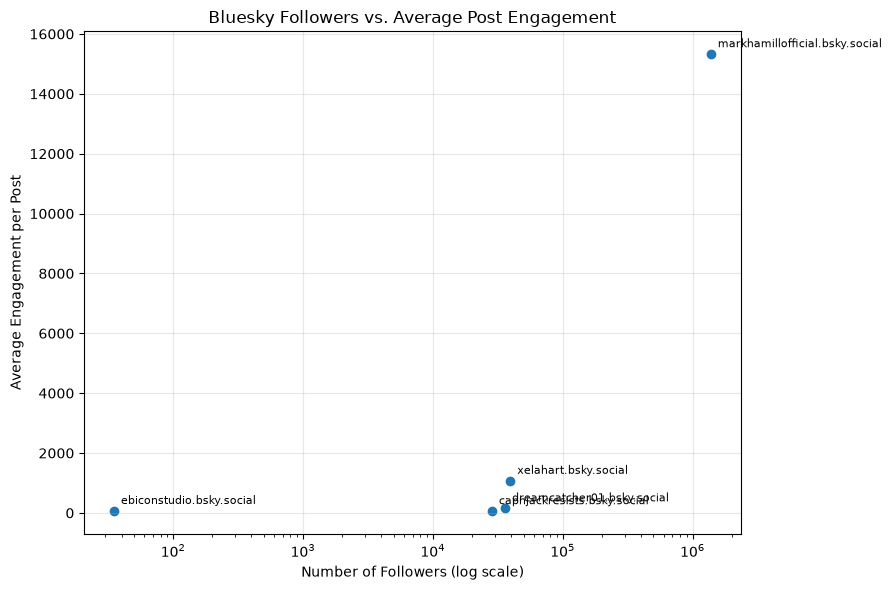

In [10]:
plt.figure(figsize=(9, 6))

plt.scatter(
    account_summary["followers"],
    account_summary["avg_engagement"]
)

plt.xscale("log")

for _, row in account_summary.iterrows():
    plt.annotate(
        row["handle"],
        (row["followers"], row["avg_engagement"]),
        fontsize=8,
        xytext=(5, 5),
        textcoords="offset points"
    )

plt.xlabel("Number of Followers (log scale)")
plt.ylabel("Average Engagement per Post")
plt.title("Bluesky Followers vs. Average Post Engagement")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [12]:
account_summary[
    [
        "handle",
        "followers",
        "posts_collected",
        "avg_likes",
        "avg_reposts",
        "avg_replies",
        "avg_engagement"
    ]
].round(2)

,handle,followers,posts_collected,avg_likes,avg_reposts,avg_replies,avg_engagement
3,markhamillofficial.bsky.social,1383324,30,12009.00,2779.13,536.40,15324.53
4,xelahart.bsky.social,39461,30,797.17,237.50,37.50,1072.17
1,dreamcatcher01.bsky.social,36013,17,137.65,13.59,1.53,152.76
0,capnjackresists.bsky.social,28502,24,45.92,8.67,2.33,56.92
2,ebiconstudio.bsky.social,35,3,40.33,25.00,0.67,66.00


This report examined whether Bluesky accounts with more followers receive higher engagement on their posts. Among the five accounts analyzed, markhamillofficial.bsky.social had the most followers (1,383,324) and the highest average engagement (15,324.53 per post). However, xelahart.bsky.social also showed a lot of engagement, averaging 1,072.17 per post, and ebiconstudio.bsky.social averaged 66.00 despite having only 35 followers. These results generally suggest that accounts with larger audiences can receive more engagement, but follower count alone does not explain every difference. This analysis is limited by its small sample of five accounts. Engagement information can change over time and may also depend on post content, timing, and audience interests. The results do not establish that follower count causes higher engagement. Future research could include more accounts and investigate how content type and posting frequency relate to engagement.